In [ ]:
!pip install earthengine-api geemap -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 73.5 MB/s eta 0:00:00


In [ ]:
import ee
ee.Authenticate()

In [ ]:
import ee
ee.Initialize(project='ecovision-ai-507316')
print("it works")

it works


In [ ]:
!nvidia-smi

Fri Sep 11 05:41:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!wget https://huggingface.co/datasets/recursix/geo-bench-1.0/resolve/main/classification_v1.0/m-brick-kiln.zip -O m-brick-kiln.zip
!unzip -q m-brick-kiln.zip -d brick_kiln_data
!ls brick_kiln_data

--2026-09-11 05:41:21--  https://huggingface.co/datasets/recursix/geo-bench-1.0/resolve/main/classification_v1.0/m-brick-kiln.zip
Resolving huggingface.co (huggingface.co)... 18.164.174.118, 18.164.174.23, 18.164.174.55, ...
Connecting to huggingface.co (huggingface.co)|18.164.174.118|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/6555289ad782367f17952a2a/7e55ea9988ad49922c479bb134ef7fd0bf1cfcaf377dad0df66f9ba0095fc546?response-content-type=application%2Fzip&user_id=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27m-brick-kiln.zip%3B+filename%3D%22m-brick-kiln.zip%22%3B&X-Xet-Cas-Uid=public&Expires=1789108881&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjU1NTI4OWFkNzgyMzY3ZjE3OTUyYTJhLzdlNTVlYTk5ODhhZDQ5OTIyYzQ3OWJiMTM0ZWY3ZmQwYmYxY2ZjYWYzNzdkYWQwZGY2NmY5YmEwMDk1ZmM1NDZcXD9yZXNwb25zZS1jb250ZW50LXR5cGU9KiZ1c2VyX2lkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50L

In [ ]:
!ls brick_kiln_data/m-brick-kiln | head -20

0.01x_train_partition.json
0.02x_train_partition.json
0.05x_train_partition.json
0.10x_train_partition.json
0.20x_train_partition.json
0.50x_train_partition.json
1.00x_train_partition.json
band_stats.json
default_partition.json
examples_0_103.hdf5
examples_0_109.hdf5
examples_0_120.hdf5
examples_0_122.hdf5
examples_0_128.hdf5
examples_0_12.hdf5
examples_0_144.hdf5
examples_0_147.hdf5
examples_0_152.hdf5
examples_0_157.hdf5
examples_0_158.hdf5


In [ ]:
import json
import h5py

# look inside the partition file (tells us train/val/test splits)
with open('brick_kiln_data/m-brick-kiln/default_partition.json') as f:
    partition = json.load(f)
print("PARTITION TYPE:", type(partition))
print("PARTITION KEYS:", list(partition.keys()) if isinstance(partition, dict) else partition[:5])

# look inside one actual image file
with h5py.File('brick_kiln_data/m-brick-kiln/examples_0_103.hdf5', 'r') as f:
    print("\nFILE KEYS:", list(f.keys()))
    for k in f.keys():
        print(k, "->", f[k][()] if f[k].shape == () or len(f[k].shape) == 0 else f[k].shape)

PARTITION TYPE: <class 'dict'>
PARTITION KEYS: ['train', 'valid', 'test']

FILE KEYS: ['01 - Coastal aerosol', '02 - Blue', '03 - Green', '04 - Red', '05 - Vegetation Red Edge', '06 - Vegetation Red Edge', '07 - Vegetation Red Edge', '08 - NIR', '08A - Vegetation Red Edge', '09 - Water vapour', '10 - SWIR - Cirrus', '11 - SWIR', '12 - SWIR']
01 - Coastal aerosol -> (64, 64)
02 - Blue -> (64, 64)
03 - Green -> (64, 64)
04 - Red -> (64, 64)
05 - Vegetation Red Edge -> (64, 64)
06 - Vegetation Red Edge -> (64, 64)
07 - Vegetation Red Edge -> (64, 64)
08 - NIR -> (64, 64)
08A - Vegetation Red Edge -> (64, 64)
09 - Water vapour -> (64, 64)
10 - SWIR - Cirrus -> (64, 64)
11 - SWIR -> (64, 64)
12 - SWIR -> (64, 64)


In [ ]:
import h5py, json

with open('brick_kiln_data/m-brick-kiln/default_partition.json') as f:
    partition = json.load(f)
print("Number of train examples:", len(partition['train']))
print("Sample train entries:", partition['train'][:5])

with h5py.File('brick_kiln_data/m-brick-kiln/examples_0_103.hdf5', 'r') as f:
    print("\nATTRIBUTES:")
    for k, v in f.attrs.items():
        print(k, "->", v)

Number of train examples: 15063
Sample train entries: ['examples_75_67', 'examples_13_422', 'examples_61_762', 'examples_81_185', 'examples_38_156']

ATTRIBUTES:
pickle -> b'\x80\x04\x95$\x06\x00\x00\x00\x00\x00\x00}\x94(\x8c\x05label\x94K\x00\x8c\x1401 - Coastal aerosol\x94}\x94(\x8c\x04date\x94N\x8c\x07date_id\x94N\x8c\x12spatial_resolution\x94K\n\x8c\tband_info\x94\x8c\x10geobench.dataset\x94\x8c\tSentinel2\x94\x93\x94)\x81\x94}\x94(\x8c\x04name\x94h\x02\x8c\talt_names\x94\x8c\x011\x94\x8c\x0201\x94\x86\x94h\x06K<\x8c\nwavelength\x94G?\xdcZ\x1c\xac\x081\'ub\x8c\tmeta_info\x94N\x8c\ttransform\x94\x8c\x06affine\x94\x8c\x06Affine\x94\x93\x94(\x8c\x15numpy.core.multiarray\x94\x8c\x06scalar\x94\x93\x94\x8c\x05numpy\x94\x8c\x05dtype\x94\x93\x94\x8c\x02f8\x94\x89\x88\x87\x94R\x94(K\x03\x8c\x01<\x94NNNJ\xff\xff\xff\xffJ\xff\xff\xff\xffK\x00t\x94bC\x08\x00\x80\x1e\xe8}\x8c\x17?\x94\x86\x94R\x94h\x1ah C\x08\x00\x00\x00\x00\x00\x00\x00\x00\x94\x86\x94R\x94h\x1ah C\x08\x1cADA$"V@\x94\x86\x94R\x

Image shape: (64, 64, 13)
Label: 0  (0 = no kiln, 1 = kiln)


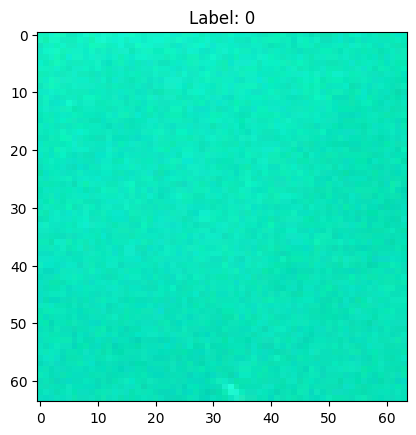

In [ ]:
import ast, io, pickle
import h5py, numpy as np, matplotlib.pyplot as plt, json

DATA_DIR = 'brick_kiln_data/m-brick-kiln'

with open(f'{DATA_DIR}/default_partition.json') as f:
    partition = json.load(f)

# A "safe" unpickler: if it hits a class it doesn't recognize (like geobench's),
# it substitutes a harmless placeholder instead of crashing.
class SafeUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        try:
            return super().find_class(module, name)
        except Exception:
            class Placeholder:
                def __init__(self, *a, **kw): pass
                def __setstate__(self, state): self.__dict__['_state'] = state
                def __reduce__(self): return (Placeholder, ())
            return Placeholder

def safe_unpickle(raw_bytes):
    return SafeUnpickler(io.BytesIO(raw_bytes)).load()

def load_example(example_id):
    path = f'{DATA_DIR}/{example_id}.hdf5'
    with h5py.File(path, 'r') as f:
        raw = f.attrs['pickle']
        raw_bytes = ast.literal_eval(raw) if isinstance(raw, str) else bytes(raw)
        meta = safe_unpickle(raw_bytes)
        label = meta['label']
        bands_order = meta['bands_order']
        image = np.stack([f[b][()] for b in bands_order], axis=-1)
    return image, label

example_id = partition['train'][0]
image, label = load_example(example_id)
print("Image shape:", image.shape)
print("Label:", label, " (0 = no kiln, 1 = kiln)")

rgb = image[:, :, [3, 2, 1]].astype(float)
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)
plt.imshow(rgb)
plt.title(f"Label: {label}")
plt.show()

In [ ]:
import ast, io, pickle
import h5py, numpy as np, json
from tqdm import tqdm

DATA_DIR = 'brick_kiln_data/m-brick-kiln'

with open(f'{DATA_DIR}/default_partition.json') as f:
    partition = json.load(f)

class SafeUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        try:
            return super().find_class(module, name)
        except Exception:
            class Placeholder:
                def __init__(self, *a, **kw): pass
                def __setstate__(self, state): self.__dict__['_state'] = state
                def __reduce__(self): return (Placeholder, ())
            return Placeholder

def safe_unpickle(raw_bytes):
    return SafeUnpickler(io.BytesIO(raw_bytes)).load()

# We only need 4 bands per our Day 1 decision: Red, Green, Blue, NIR
WANTED_BANDS = ['04 - Red', '03 - Green', '02 - Blue', '08 - NIR']

def load_example(example_id):
    path = f'{DATA_DIR}/{example_id}.hdf5'
    with h5py.File(path, 'r') as f:
        raw = f.attrs['pickle']
        raw_bytes = ast.literal_eval(raw) if isinstance(raw, str) else bytes(raw)
        meta = safe_unpickle(raw_bytes)
        label = meta['label']
        image = np.stack([f[b][()] for b in WANTED_BANDS], axis=-1)  # (64, 64, 4)
    return image, label

def load_split(example_ids, name):
    images, labels = [], []
    for eid in tqdm(example_ids, desc=f"Loading {name}"):
        img, lbl = load_example(eid)
        images.append(img)
        labels.append(lbl)
    return np.array(images), np.array(labels)

X_train, y_train = load_split(partition['train'], "train")
X_valid, y_valid = load_split(partition['valid'], "valid")
X_test, y_test = load_split(partition['test'], "test")

print("Train:", X_train.shape, y_train.shape, "kilns:", y_train.sum())
print("Valid:", X_valid.shape, y_valid.shape, "kilns:", y_valid.sum())
print("Test:", X_test.shape, y_test.shape, "kilns:", y_test.sum())

# Save so we never have to redo this slow step again
np.save('/content/X_train.npy', X_train)
np.save('/content/y_train.npy', y_train)
np.save('/content/X_valid.npy', X_valid)
np.save('/content/y_valid.npy', y_valid)
np.save('/content/X_test.npy', X_test)
np.save('/content/y_test.npy', y_test)
print("Saved all files.")

Loading test: 100%|██████████| 999/999 [00:05<00:00, 172.14it/s]


Train: (15063, 64, 64, 4) (15063,) kilns: 5063
Valid: (999, 64, 64, 4) (999,) kilns: 336
Test: (999, 64, 64, 4) (999,) kilns: 336
Saved all files.


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
import gc

X_train = np.load('/content/X_train.npy')
y_train = np.load('/content/y_train.npy')
X_valid = np.load('/content/X_valid.npy')
y_valid = np.load('/content/y_valid.npy')

X_train_rgb = X_train[:, :, :, :3].astype('float32')
X_valid_rgb = X_valid[:, :, :, :3].astype('float32')
del X_train, X_valid
gc.collect()

# compute the 2/98 percentile stats ONCE — these are just a few scalars per channel
lo = np.percentile(X_train_rgb, 2, axis=(0, 1, 2)).astype('float32')
hi = np.percentile(X_train_rgb, 98, axis=(0, 1, 2)).astype('float32')

def preprocess(x, y):
    x = tf.clip_by_value((x - lo) / (hi - lo + 1e-6), 0, 1) * 255.0
    x = tf.image.resize(x, [128, 128])
    return x, y

BATCH = 32

train_ds = (tf.data.Dataset.from_tensor_slices((X_train_rgb, y_train))
            .shuffle(len(y_train))
            .batch(BATCH)
            .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))

valid_ds = (tf.data.Dataset.from_tensor_slices((X_valid_rgb, y_valid))
            .batch(BATCH)
            .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', input_shape=(128, 128, 3), pooling='avg'
)
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight = {int(c): w for c, w in zip(classes, weights)}
print("Class weights:", class_weight)

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    class_weight=class_weight
)

model.save('/content/baseline_model_v2.keras')
print("Done training v2.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Class weights: {0: np.float64(0.75315), 1: np.float64(1.4875567845151096)}
Epoch 1/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 69s 87ms/step - accuracy: 0.8976 - loss: 0.2496 - val_accuracy: 0.9389 - val_loss: 0.1717
Epoch 2/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9282 - loss: 0.1941 - val_accuracy: 0.9449 - val_loss: 0.1569
Epoch 3/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9343 - loss: 0.1809 - val_accuracy: 0.9489 - val_loss: 0.1493
Epoch 4/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9395 - loss: 0.1664 - val_accuracy: 0.9439 - val_loss: 0.1522
Epoch 5/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9465 - loss: 0.1487 - val_accuracy: 0.9459 - val_loss: 0.1508
Epoch 6/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9493 - loss: 0.1435 - val_accuracy: 0.9349 - val_loss: 0.1787
Epoch 7/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9490 - loss: 0.1405 - val_accura

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '/content/baseline_model_v2.keras',
        save_best_only=True,
        monitor='val_loss',
        mode='min'
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9616 - loss: 0.1127 - val_accuracy: 0.9550 - val_loss: 0.1449
Epoch 2/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9612 - loss: 0.1090 - val_accuracy: 0.9520 - val_loss: 0.1538
Epoch 3/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9623 - loss: 0.1083 - val_accuracy: 0.9640 - val_loss: 0.1267
Epoch 4/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9629 - loss: 0.1022 - val_accuracy: 0.9399 - val_loss: 0.1750
Epoch 5/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9657 - loss: 0.0999 - val_accuracy: 0.9339 - val_loss: 0.1803
Epoch 6/10
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9677 - loss: 0.0944 - val_accuracy: 0.9600 - val_loss: 0.1451


In [ ]:
!wget https://esaikawa.files.wordpress.com/2019/06/kathmandu_brick_kiln_emissions.xlsx -O kiln_emissions.xlsx
import pandas as pd
xl = pd.ExcelFile('kiln_emissions.xlsx')
print(xl.sheet_names)
for s in xl.sheet_names:
    print(f"\n--- {s} ---")
    print(xl.parse(s).head())

--2026-09-11 05:48:52--  https://esaikawa.files.wordpress.com/2019/06/kathmandu_brick_kiln_emissions.xlsx
Resolving esaikawa.files.wordpress.com (esaikawa.files.wordpress.com)... 192.0.72.23, 192.0.72.22
Connecting to esaikawa.files.wordpress.com (esaikawa.files.wordpress.com)|192.0.72.23|:443... connected.
HTTP request sent, awaiting response... 302 Moved Temporarily
Location: https://esaikawa.wordpress.com/wp-content/uploads/2019/06/kathmandu_brick_kiln_emissions.xlsx [following]
--2026-09-11 05:48:52--  https://esaikawa.wordpress.com/wp-content/uploads/2019/06/kathmandu_brick_kiln_emissions.xlsx
Resolving esaikawa.wordpress.com (esaikawa.wordpress.com)... 192.0.78.13, 192.0.78.12
Connecting to esaikawa.wordpress.com (esaikawa.wordpress.com)|192.0.78.13|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 21296 (21K) [application/vnd.openxmlformats-officedocument.spreadsheetml]
Saving to: ‘kiln_emissions.xlsx’

kiln_emissions.xlsx 100%[===================>]  20.8

In [ ]:
df = pd.read_excel('kiln_emissions.xlsx', sheet_name='Kathmandu_Brick_Kiln_emissions', header=1)
print(df.shape)
print(df.columns.tolist())
print(df[['Type', 'Longitude', 'Latitude']].head(15))
print("\nType counts:")
print(df['Type'].value_counts())
print("\nMissing coordinates:", df[['Longitude','Latitude']].isna().sum().sum())
print("\nLon range:", df['Longitude'].min(), "-", df['Longitude'].max())
print("Lat range:", df['Latitude'].min(), "-", df['Latitude'].max())

(112, 23)
['Type', 'Longitude', 'Latitude', 'CO', 'NO', 'SO2', 'EC', 'OC', 'Other_PM2.5', 'SO4', 'Ethane', 'Propane', 'Butane ', 'Pentane ', 'Hexane', 'Benzene', 'Toluene', 'Xylene', 'Acid', 'Alkenes', 'Alkanes', 'Acetone', 'Achonol']
     Type  Longitude  Latitude
0   FCBTK     85.444    27.658
1   FCBTK     85.446    27.656
2   FCBTK     85.450    27.654
3   FCBTK     85.469    27.674
4   FCBTK     85.470    27.675
5   FCBTK     85.253    27.679
6   FCBTK     85.229    27.698
7   FCBTK     85.290    27.617
8   FCBTK     85.291    27.618
9   FCBTK     85.256    27.677
10  FCBTK     85.344    27.651
11  FCBTK     85.344    27.592
12  FCBTK     85.347    27.644
13  FCBTK     85.348    27.647
14  FCBTK     85.348    27.637

Type counts:
Type
Zig-Zag         63
FCBTK           46
Hoffman kiln     2
VSBK             1
Name: count, dtype: int64

Missing coordinates: 0

Lon range: 85.21 - 85.478
Lat range: 27.572 - 27.706


In [ ]:
import ee
ee.Initialize(project='ecovision-ai-507316')
print("it works")

it works


In [ ]:
districts = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq('ADM0_NAME', 'Nepal')) \
    .filter(ee.Filter.inList('ADM2_NAME', ['Kathmandu', 'Lalitpur', 'Bhaktapur']))

print("Number of districts found:", districts.size().getInfo())

kathmandu_valley = districts.union()

# quick visual sanity check
import geemap
Map = geemap.Map(center=[27.7, 85.35], zoom=10)
Map.addLayer(kathmandu_valley, {'color': 'red'}, 'Kathmandu Valley boundary')

kiln_fc = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([row.Longitude, row.Latitude]), {'type': row.Type})
    for row in df.itertuples()
])
Map.addLayer(kiln_fc, {'color': 'yellow'}, 'Known kilns')
Map

Number of districts found: 0


Map(center=[27.7, 85.35], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [ ]:
nepal = ee.FeatureCollection("FAO/GAUL/2015/level2").filter(ee.Filter.eq('ADM0_NAME', 'Nepal'))
print("Total districts in Nepal:", nepal.size().getInfo())
print(nepal.aggregate_array('ADM2_NAME').getInfo())

Total districts in Nepal: 14
['Bagmati', 'Janakpur', 'Narayani', 'Koshi', 'Mechi', 'Sagarmatha', 'Mahakali', 'Seti', 'Karnali', 'Rapti', 'Bheri', 'Dhawalagiri', 'Gandaki', 'Lumbini']


In [ ]:
import geopandas as gpd
import json

!wget -q "https://raw.githubusercontent.com/manishacharya60/nepal-geojson/main/Nepal_Administrative_Boundary_District.geojson" -O nepal_districts.geojson

gdf = gpd.read_file('nepal_districts.geojson')
valley_gdf = gdf[gdf['DISTRICT'].isin(['Kathmandu', 'Lalitpur', 'Bhaktapur'])]
print("Districts found:", valley_gdf['DISTRICT'].tolist())

# convert to an Earth Engine FeatureCollection
valley_geojson = json.loads(valley_gdf.to_json())
kathmandu_valley = ee.FeatureCollection(valley_geojson)

# visual check
import geemap
Map = geemap.Map(center=[27.7, 85.35], zoom=10)
Map.addLayer(kathmandu_valley, {'color': 'red'}, 'Kathmandu Valley (3 districts)')

kiln_fc = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([row.Longitude, row.Latitude]), {'type': row.Type})
    for row in df.itertuples()
])
Map.addLayer(kiln_fc, {'color': 'yellow'}, 'Known kilns')
Map

Districts found: ['Bhaktapur', 'Kathmandu', 'Lalitpur']


Map(center=[27.7, 85.35], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

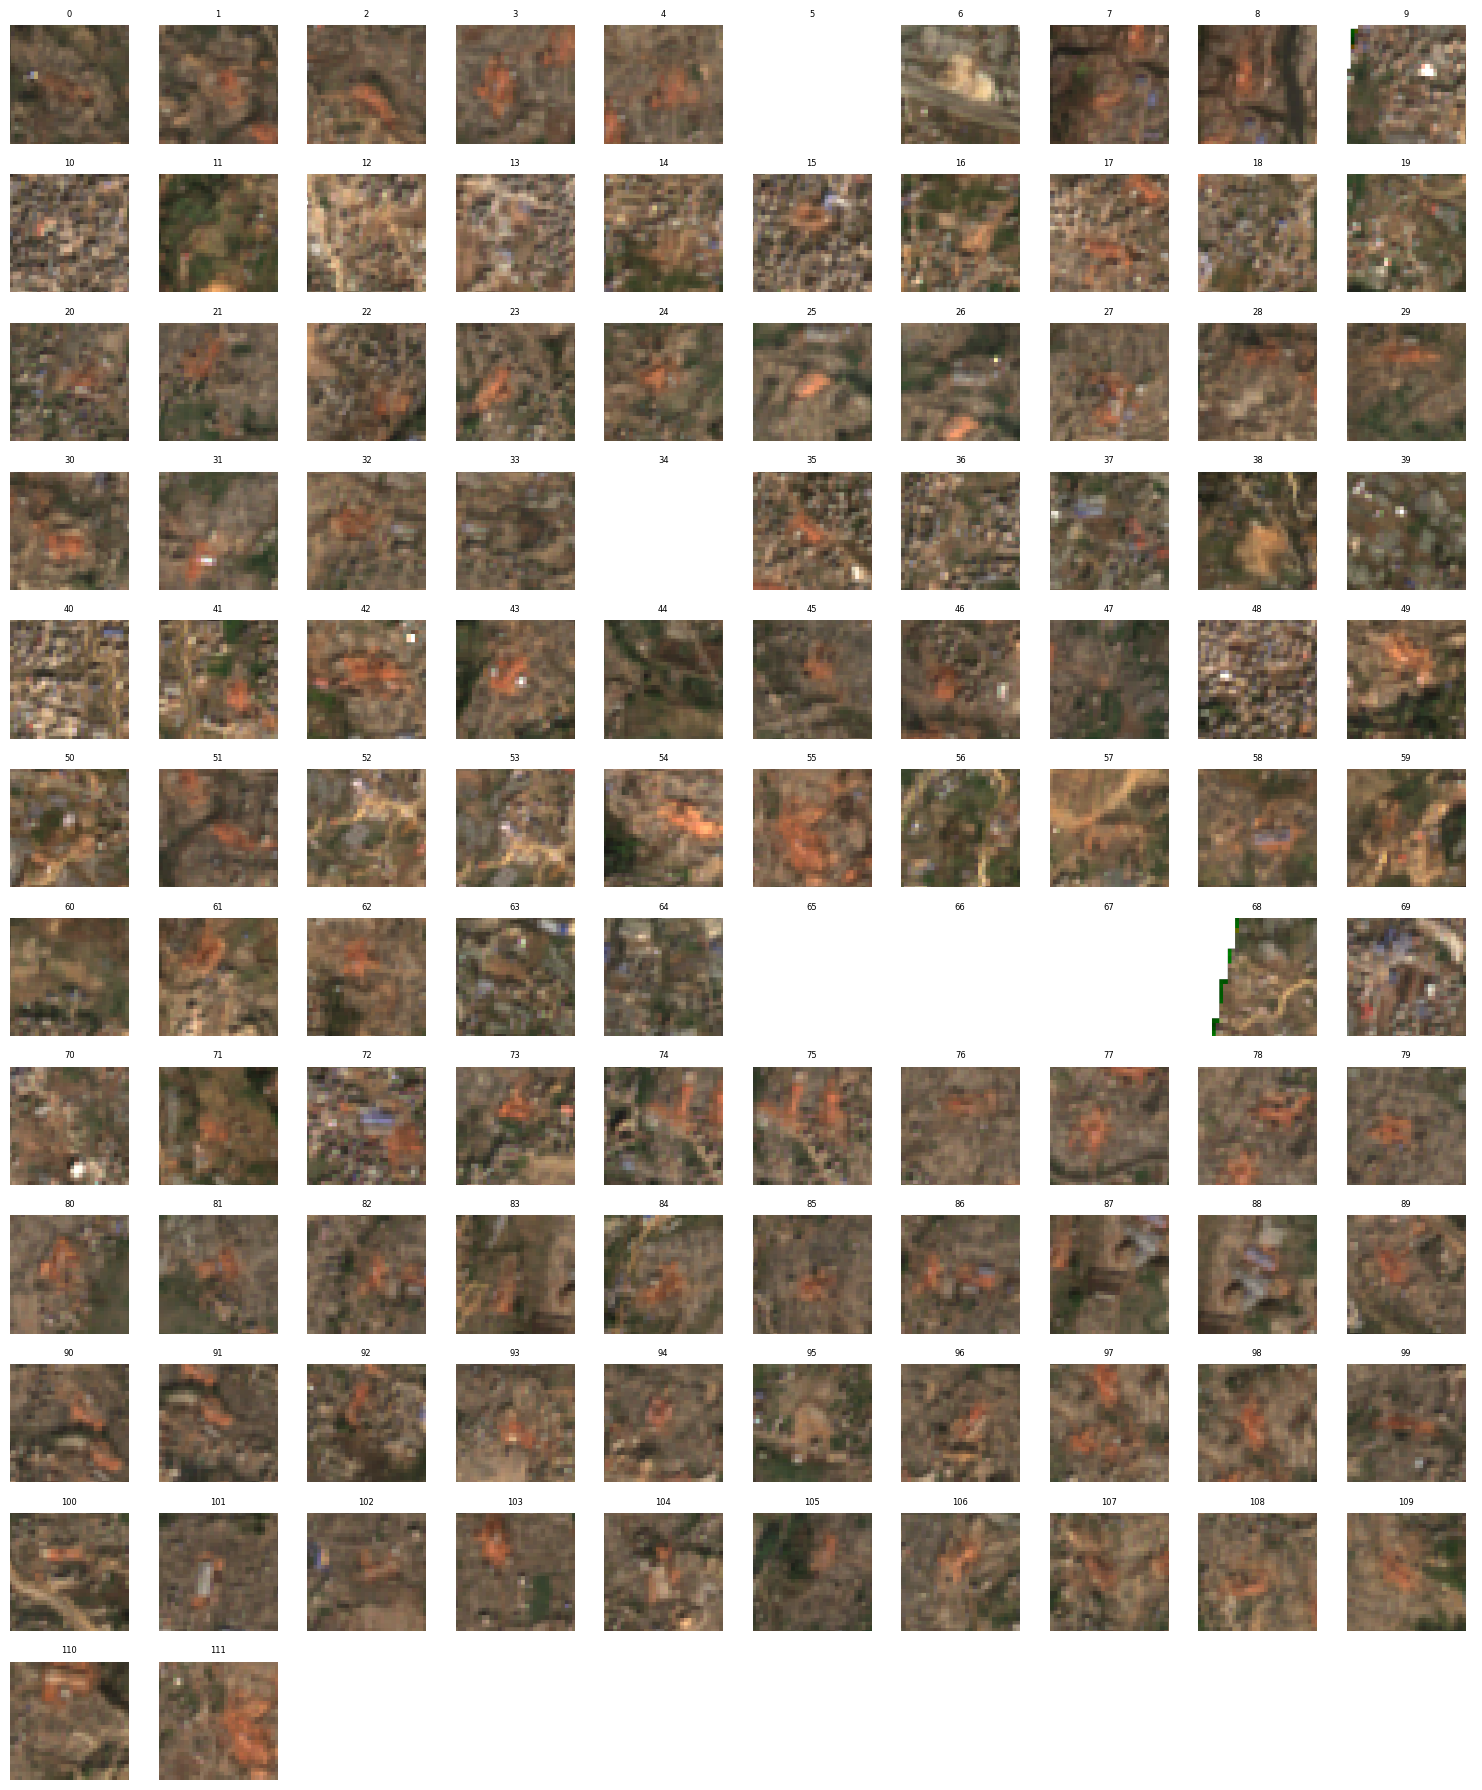

In [ ]:
import ee
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

def get_thumbnail(lon, lat, buffer_m=150, size=128):
    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(buffer_m).bounds()

    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(point)
          .filterDate('2025-12-01', '2026-05-01')   # dry season = kilns operating, most visible
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30))
          .sort('CLOUDY_PIXEL_PERCENTAGE'))

    image = s2.first()
    vis = image.visualize(bands=['B4', 'B3', 'B2'], min=0, max=3000)
    url = vis.getThumbURL({'region': region, 'dimensions': f'{size}x{size}', 'format': 'png'})
    return Image.open(BytesIO(requests.get(url).content))

n = len(df)
cols = 10
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols*1.5, rows*1.5))

for i, row in enumerate(df.itertuples()):
    ax = axes[i // cols, i % cols]
    try:
        img = get_thumbnail(row.Longitude, row.Latitude)
        ax.imshow(img)
    except Exception:
        ax.text(0.5, 0.5, 'no img', ha='center', fontsize=6)
    ax.set_title(str(i), fontsize=6)
    ax.axis('off')

for j in range(n, rows * cols):
    axes[j // cols, j % cols].axis('off')

plt.tight_layout()
plt.savefig('/content/kiln_contact_sheet.png', dpi=150)
plt.show()

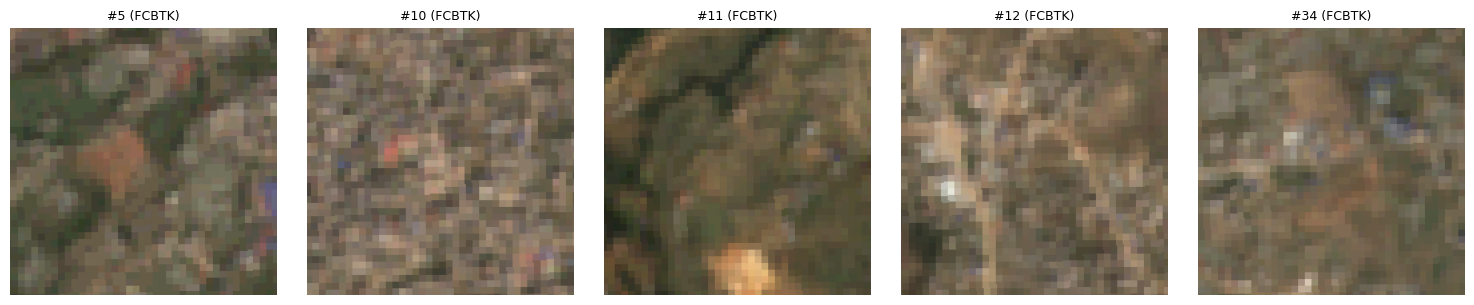

In [ ]:
def get_thumbnail_robust(lon, lat, buffer_m=200, size=200):
    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(buffer_m).bounds()

    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(point)
          .filterDate('2023-01-01', '2026-06-01')
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 50)))

    image = s2.median()  # composite instead of a single scene — robust to cloud gaps
    vis = image.visualize(bands=['B4', 'B3', 'B2'], min=0, max=3000)
    url = vis.getThumbURL({'region': region, 'dimensions': f'{size}x{size}', 'format': 'png'})
    return Image.open(BytesIO(requests.get(url).content))

# re-check the blanks and the questionable ones, larger and clearer
check_indices = [5, 10, 11, 12, 34]
fig, axes = plt.subplots(1, len(check_indices), figsize=(len(check_indices)*3, 3))

for ax, idx in zip(axes, check_indices):
    row = df.iloc[idx]
    try:
        img = get_thumbnail_robust(row.Longitude, row.Latitude)
        ax.imshow(img)
    except Exception as e:
        ax.text(0.5, 0.5, f'failed:\n{e}', ha='center', fontsize=7, wrap=True)
    ax.set_title(f"#{idx} ({row.Type})", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/questionable_kilns_closeup.png', dpi=150)
plt.show()

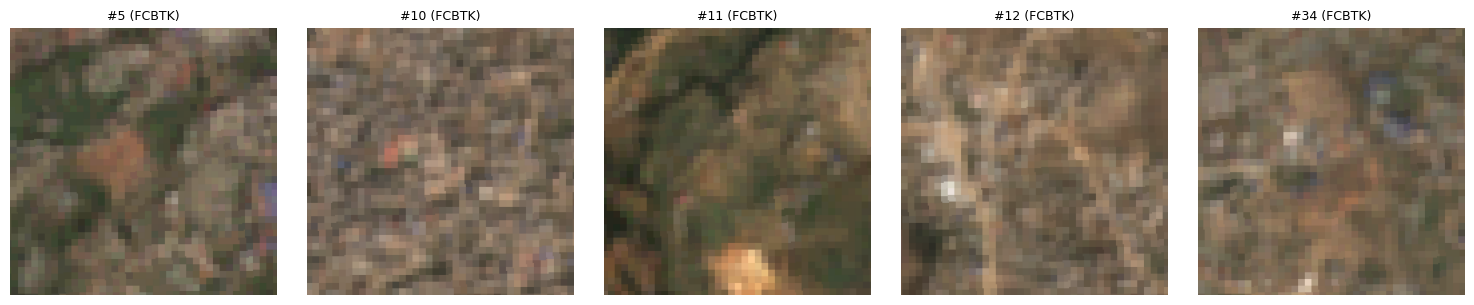

In [ ]:
def get_dry_season_composite(lon, lat, buffer_m=200, size=200):
    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(buffer_m).bounds()

    # stack Dec–May windows across several recent dry seasons
    dry_seasons = [
        ('2023-12-01', '2024-05-01'),
        ('2024-12-01', '2025-05-01'),
        ('2025-12-01', '2026-05-01'),
    ]

    collections = [
        ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(point)
          .filterDate(start, end)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
        for start, end in dry_seasons
    ]
    merged = collections[0]
    for c in collections[1:]:
        merged = merged.merge(c)

    image = merged.median()
    vis = image.visualize(bands=['B4', 'B3', 'B2'], min=0, max=3000)
    url = vis.getThumbURL({'region': region, 'dimensions': f'{size}x{size}', 'format': 'png'})
    return Image.open(BytesIO(requests.get(url).content))

check_indices = [5, 10, 11, 12, 34]
fig, axes = plt.subplots(1, len(check_indices), figsize=(len(check_indices)*3, 3))

for ax, idx in zip(axes, check_indices):
    row = df.iloc[idx]
    try:
        img = get_dry_season_composite(row.Longitude, row.Latitude)
        ax.imshow(img)
    except Exception as e:
        ax.text(0.5, 0.5, f'failed:\n{e}', ha='center', fontsize=7, wrap=True)
    ax.set_title(f"#{idx} ({row.Type})", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/dry_season_recheck.png', dpi=150)
plt.show()

In [ ]:
print(df.iloc[34][['Longitude', 'Latitude']])

Longitude    85.255
Latitude     27.695
Name: 34, dtype: object


In [ ]:
CORRECTED_12_LON = 85.3426945
CORRECTED_12_LAT = 27.6439851

df_clean = df.copy()
df_clean.loc[12, 'Longitude'] = CORRECTED_12_LON
df_clean.loc[12, 'Latitude'] = CORRECTED_12_LAT
df_clean = df_clean.drop(index=[5, 10, 11, 34]).reset_index(drop=True)

assert df_clean['Longitude'].apply(lambda x: isinstance(x, (int, float))).all()
assert df_clean['Latitude'].apply(lambda x: isinstance(x, (int, float))).all()
print(f"Cleaned: {len(df_clean)} kilns, all coordinates valid")

Cleaned: 108 kilns, all coordinates valid


In [ ]:
import geopandas as gpd
from shapely.geometry import Point
import numpy as np

# reproject to a metric CRS (UTM zone 45N covers Nepal) so buffering is in real meters
valley_utm = valley_gdf.to_crs(epsg=32645)
valley_union = valley_utm.union_all()

# build kiln points in the same metric CRS, buffer each by 300m as an exclusion zone
kiln_points_utm = gpd.GeoSeries(
    [Point(lon, lat) for lon, lat in zip(df_clean['Longitude'], df_clean['Latitude'])],
    crs='EPSG:4326'
).to_crs(epsg=32645)

exclusion_zone = kiln_points_utm.buffer(300).union_all()
sampling_area = valley_union.difference(exclusion_zone)

# rejection-sample random points inside the valley but outside all exclusion zones
minx, miny, maxx, maxy = sampling_area.bounds
negative_points_utm = []
np.random.seed(42)

while len(negative_points_utm) < len(df_clean):
    x = np.random.uniform(minx, maxx)
    y = np.random.uniform(miny, maxy)
    p = Point(x, y)
    if sampling_area.contains(p):
        negative_points_utm.append(p)

negative_gseries = gpd.GeoSeries(negative_points_utm, crs=32645).to_crs(epsg=4326)

negatives_df = pd.DataFrame({
    'Longitude': [p.x for p in negative_gseries],
    'Latitude': [p.y for p in negative_gseries],
    'label': 0
})

print(f"Generated {len(negatives_df)} negative points")
negatives_df.to_csv('/content/kathmandu_negatives.csv', index=False)

Generated 108 negative points


In [ ]:
Map2 = geemap.Map(center=[27.7, 85.35], zoom=10)
Map2.addLayer(kathmandu_valley, {'color': 'red'}, 'Valley boundary')
Map2.addLayer(ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.Longitude, r.Latitude])) for r in df_clean.itertuples()]), {'color': 'yellow'}, 'Kilns')
Map2.addLayer(ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.Longitude, r.Latitude])) for r in negatives_df.itertuples()]), {'color': 'blue'}, 'Negatives')
Map2

Map(center=[27.7, 85.35], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [ ]:
from tqdm import tqdm

def get_patch_array(lon, lat, bands=['B4','B3','B2','B8'], patch_size=64, scale=10):
    point = ee.Geometry.Point([lon, lat])
    half = patch_size * scale / 2  # meters, half-width of the patch
    region = point.buffer(half).bounds()

    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(point)
          .filterDate('2025-12-01', '2026-05-01')   # dry season, kilns operating
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
          .median())

    image = s2.select(bands)
    sampled = image.sampleRectangle(region=region, defaultValue=0)
    arrays = [np.array(sampled.get(b).getInfo(), dtype='float32') for b in bands]

    # enforce exact patch_size x patch_size (sampleRectangle can be off by a pixel)
    padded = np.zeros((patch_size, patch_size, len(bands)), dtype='float32')
    h = min(patch_size, arrays[0].shape[0])
    w = min(patch_size, arrays[0].shape[1])
    for i, a in enumerate(arrays):
        padded[:h, :w, i] = a[:h, :w]
    return padded

# combine kilns (label=1) and negatives (label=0) into one list to process
all_points = list(zip(df_clean['Longitude'], df_clean['Latitude'], [1]*len(df_clean))) + \
             list(zip(negatives_df['Longitude'], negatives_df['Latitude'], [0]*len(negatives_df)))

X_kathmandu = []
y_kathmandu = []
failed = []

for i, (lon, lat, label) in enumerate(tqdm(all_points)):
    try:
        patch = get_patch_array(lon, lat)
        X_kathmandu.append(patch)
        y_kathmandu.append(label)
    except Exception as e:
        failed.append((i, lon, lat, str(e)))
    if i % 20 == 0:
        np.save('/content/X_kathmandu_partial.npy', np.array(X_kathmandu))
        np.save('/content/y_kathmandu_partial.npy', np.array(y_kathmandu))

X_kathmandu = np.array(X_kathmandu)
y_kathmandu = np.array(y_kathmandu)

print(f"Success: {len(X_kathmandu)}, Failed: {len(failed)}")
np.save('/content/X_kathmandu.npy', X_kathmandu)
np.save('/content/y_kathmandu.npy', y_kathmandu)

100%|██████████| 216/216 [11:37<00:00,  3.23s/it]

Success: 216, Failed: 0


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import tensorflow as tf

# use the SAME percentile stats from training — not recomputed from Kathmandu data,
# otherwise this stops being a fair "unseen data" test
X_train = np.load('/content/X_train.npy')
X_train_rgb = X_train[:, :, :, :3].astype('float32')
lo = np.percentile(X_train_rgb, 2, axis=(0, 1, 2)).astype('float32')
hi = np.percentile(X_train_rgb, 98, axis=(0, 1, 2)).astype('float32')

# X_kathmandu is (N, 64, 64, 4) in order [R, G, B, NIR] — drop NIR, keep RGB
X_kath_rgb = X_kathmandu[:, :, :, :3].astype('float32')
X_kath_norm = np.clip((X_kath_rgb - lo) / (hi - lo + 1e-6), 0, 1) * 255.0
X_kath_resized = tf.image.resize(X_kath_norm, [128, 128]).numpy()

model = tf.keras.models.load_model('/content/baseline_model_v2.keras')

probs = model.predict(X_kath_resized, batch_size=32).flatten()
preds = (probs > 0.5).astype(int)

print(classification_report(y_kathmandu, preds, target_names=['Non-kiln', 'Kiln']))
print("\nConfusion matrix:")
print(confusion_matrix(y_kathmandu, preds))

7/7 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step
              precision    recall  f1-score   support

    Non-kiln       0.50      1.00      0.67       108
        Kiln       0.00      0.00      0.00       108

    accuracy                           0.50       216
   macro avg       0.25      0.50      0.33       216
weighted avg       0.25      0.50      0.33       216


Confusion matrix:
[[108   0]
 [108   0]]


In [ ]:
print("X_train_rgb   — min:", X_train_rgb.min(), "max:", X_train_rgb.max(), "mean:", X_train_rgb.mean())
print("X_kath_rgb    — min:", X_kath_rgb.min(), "max:", X_kath_rgb.max(), "mean:", X_kath_rgb.mean())
print("lo:", lo, " hi:", hi)
print("X_kath_norm   — min:", X_kath_norm.min(), "max:", X_kath_norm.max(), "mean:", X_kath_norm.mean())
print("\nprobs — min:", probs.min(), "max:", probs.max(), "mean:", probs.mean())

X_train_rgb   — min: 48.666668 max: 5365.3335 mean: 785.486
X_kath_rgb    — min: 0.0 max: 2047.0 mean: 0.14132032
lo: [216.59058 333.41666 248.     ]  hi: [1709.3334 1452.     1146.6666]
X_kath_norm   — min: 0.0 max: 255.0 mean: 0.01578863

probs — min: 1.9937532e-09 max: 2.242505e-09 mean: 2.0043387e-09


In [ ]:
def get_patch_array(lon, lat, bands=['B4','B3','B2','B8'], patch_size=64, scale=10):
    point = ee.Geometry.Point([lon, lat])
    half = patch_size * scale / 2
    region = point.buffer(half).bounds()

    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(point)
          .filterDate('2025-12-01', '2026-05-01')
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
          .median())

    # THE FIX: re-establish an explicit projection/scale after the reducer
    image = s2.select(bands).reproject(crs='EPSG:32645', scale=scale)

    sampled = image.sampleRectangle(region=region, defaultValue=0)
    arrays = [np.array(sampled.get(b).getInfo(), dtype='float32') for b in bands]

    padded = np.zeros((patch_size, patch_size, len(bands)), dtype='float32')
    h = min(patch_size, arrays[0].shape[0])
    w = min(patch_size, arrays[0].shape[1])
    for i, a in enumerate(arrays):
        padded[:h, :w, i] = a[:h, :w]
    return padded

In [ ]:
test_patch = get_patch_array(df_clean.iloc[0]['Longitude'], df_clean.iloc[0]['Latitude'])
print("shape:", test_patch.shape)
print("min:", test_patch.min(), "max:", test_patch.max(), "mean:", test_patch.mean())
print("nonzero fraction:", (test_patch != 0).mean())

shape: (64, 64, 4)
min: 393.5 max: 4169.5 mean: 1265.225
nonzero fraction: 1.0


In [ ]:
X_kathmandu = []
y_kathmandu = []
failed = []

for i, (lon, lat, label) in enumerate(tqdm(all_points)):
    try:
        patch = get_patch_array(lon, lat)
        X_kathmandu.append(patch)
        y_kathmandu.append(label)
    except Exception as e:
        failed.append((i, lon, lat, str(e)))
    if i % 20 == 0:
        np.save('/content/X_kathmandu_partial.npy', np.array(X_kathmandu))
        np.save('/content/y_kathmandu_partial.npy', np.array(y_kathmandu))

X_kathmandu = np.array(X_kathmandu)
y_kathmandu = np.array(y_kathmandu)

print(f"Success: {len(X_kathmandu)}, Failed: {len(failed)}")
np.save('/content/X_kathmandu.npy', X_kathmandu)
np.save('/content/y_kathmandu.npy', y_kathmandu)

100%|██████████| 216/216 [13:03<00:00,  3.63s/it]

Success: 216, Failed: 0


In [ ]:
print("X_kathmandu shape:", X_kathmandu.shape)
print("mean:", X_kathmandu.mean(), " min:", X_kathmandu.min(), " max:", X_kathmandu.max())
print("nonzero fraction:", (X_kathmandu != 0).mean())

X_kathmandu shape: (216, 64, 64, 4)
mean: 1234.426  min: 38.0  max: 9003.0
nonzero fraction: 1.0


In [ ]:
X_kath_rgb = X_kathmandu[:, :, :, :3].astype('float32')
X_kath_norm = np.clip((X_kath_rgb - lo) / (hi - lo + 1e-6), 0, 1) * 255.0
X_kath_resized = tf.image.resize(X_kath_norm, [128, 128]).numpy()

probs = model.predict(X_kath_resized, batch_size=32).flatten()
preds = (probs > 0.5).astype(int)

print("probs — min:", probs.min(), "max:", probs.max(), "mean:", probs.mean())
print()
print(classification_report(y_kathmandu, preds, target_names=['Non-kiln', 'Kiln']))
print("\nConfusion matrix:")
print(confusion_matrix(y_kathmandu, preds))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
probs — min: 1.206727e-08 max: 0.99962103 mean: 0.30489412

              precision    recall  f1-score   support

    Non-kiln       0.64      0.89      0.74       108
        Kiln       0.82      0.49      0.61       108

    accuracy                           0.69       216
   macro avg       0.73      0.69      0.68       216
weighted avg       0.73      0.69      0.68       216


Confusion matrix:
[[96 12]
 [55 53]]


In [ ]:
print("Base model trainable:", model.layers[0].trainable)

Base model trainable: False


In [ ]:
kiln_mask = y_kathmandu == 1
kiln_types = df_clean['Type'].values
kiln_preds = preds[:108]
kiln_probs = probs[:108]

results_by_type = pd.DataFrame({'Type': kiln_types, 'pred': kiln_preds, 'prob': kiln_probs, 'correct': kiln_preds == 1})
print(results_by_type.groupby('Type')['correct'].agg(['mean', 'count']))

                  mean  count
Type                         
FCBTK         0.404762     42
Hoffman kiln  1.000000      2
VSBK          0.000000      1
Zig-Zag       0.539683     63


In [ ]:
def get_ndvi_evi(lon, lat, buffer_m=100, start='2025-12-01', end='2026-05-01'):
    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(buffer_m)

    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(point)
          .filterDate(start, end)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
          .median())

    nir = s2.select('B8').divide(10000)
    red = s2.select('B4').divide(10000)
    blue = s2.select('B2').divide(10000)

    ndvi = nir.subtract(red).divide(nir.add(red)).rename('NDVI')
    evi = nir.subtract(red).multiply(2.5).divide(
        nir.add(red.multiply(6)).subtract(blue.multiply(7.5)).add(1)
    ).rename('EVI')

    stats = ndvi.addBands(evi).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=region, scale=10, maxPixels=1e9
    )
    return stats.getInfo()

all_env_points = list(zip(df_clean['Longitude'], df_clean['Latitude'], [1]*len(df_clean))) + \
                  list(zip(negatives_df['Longitude'], negatives_df['Latitude'], [0]*len(negatives_df)))

results = []
for i, (lon, lat, label) in enumerate(tqdm(all_env_points)):
    try:
        stats = get_ndvi_evi(lon, lat)
        stats.update({'Longitude': lon, 'Latitude': lat, 'is_kiln': label})
        results.append(stats)
    except Exception as e:
        results.append({'Longitude': lon, 'Latitude': lat, 'is_kiln': label, 'NDVI': None, 'EVI': None})
    if i % 20 == 0:
        pd.DataFrame(results).to_csv('/content/ndvi_evi_partial.csv', index=False)

env_df = pd.DataFrame(results)
env_df.to_csv('/content/ndvi_evi_full.csv', index=False)
print(env_df.groupby('is_kiln')[['NDVI', 'EVI']].agg(['mean', 'std', 'count']))

100%|██████████| 216/216 [05:16<00:00,  1.47s/it]

             NDVI                       EVI                
             mean       std count      mean       std count
is_kiln                                                    
0        0.517137  0.186053   108  0.320471  0.121697   108
1        0.221940  0.058291   108  0.141943  0.039891   108


In [ ]:
from scipy import stats as sps

kiln_ndvi = env_df[env_df['is_kiln']==1]['NDVI'].dropna()
nonkiln_ndvi = env_df[env_df['is_kiln']==0]['NDVI'].dropna()
kiln_evi = env_df[env_df['is_kiln']==1]['EVI'].dropna()
nonkiln_evi = env_df[env_df['is_kiln']==0]['EVI'].dropna()

t_ndvi, p_ndvi = sps.ttest_ind(kiln_ndvi, nonkiln_ndvi)
t_evi, p_evi = sps.ttest_ind(kiln_evi, nonkiln_evi)

print(f"NDVI — kiln mean: {kiln_ndvi.mean():.4f}, non-kiln mean: {nonkiln_ndvi.mean():.4f}, p={p_ndvi:.4g}")
print(f"EVI  — kiln mean: {kiln_evi.mean():.4f}, non-kiln mean: {nonkiln_evi.mean():.4f}, p={p_evi:.4g}")

NDVI — kiln mean: 0.2219, non-kiln mean: 0.5171, p=1.412e-37
EVI  — kiln mean: 0.1419, non-kiln mean: 0.3205, p=1.34e-33


In [ ]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    pooled_std = np.sqrt(((na-1)*a.std()**2 + (nb-1)*b.std()**2) / (na+nb-2))
    return (a.mean() - b.mean()) / pooled_std

print("NDVI Cohen's d:", cohens_d(nonkiln_ndvi, kiln_ndvi))
print("EVI Cohen's d:", cohens_d(nonkiln_evi, kiln_evi))

NDVI Cohen's d: 2.1412128859910093
EVI Cohen's d: 1.9714276361464524


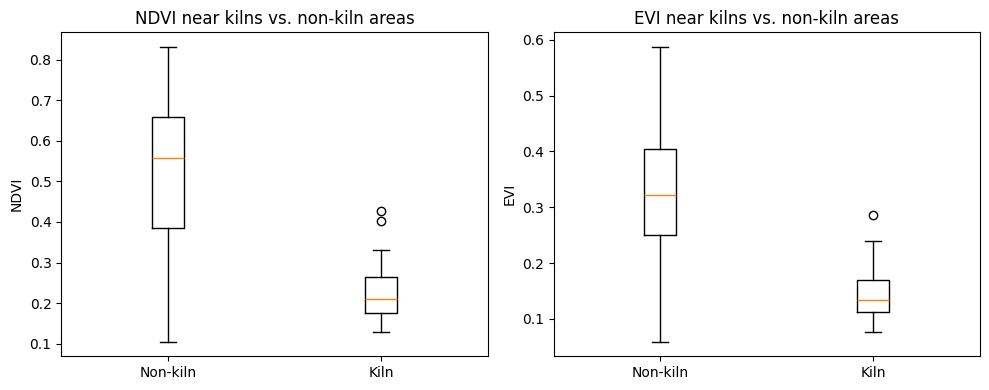

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col, name in zip(axes, ['NDVI', 'EVI'], ['NDVI', 'EVI']):
    data = [env_df[env_df['is_kiln']==0][col].dropna(), env_df[env_df['is_kiln']==1][col].dropna()]
    ax.boxplot(data, labels=['Non-kiln', 'Kiln'])
    ax.set_title(f'{name} near kilns vs. non-kiln areas')
    ax.set_ylabel(name)

plt.tight_layout()
plt.savefig('/content/ndvi_evi_boxplot.png', dpi=150)
plt.show()

In [ ]:
Map3 = geemap.Map(center=[27.7, 85.35], zoom=11)
ndvi_layer = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterBounds(kathmandu_valley) \
    .filterDate('2025-12-01', '2026-05-01') \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40)) \
    .median()
ndvi_img = ndvi_layer.normalizedDifference(['B8', 'B4']).rename('NDVI')
Map3.addLayer(ndvi_img.clip(kathmandu_valley), {'min': 0, 'max': 0.8, 'palette': ['brown','yellow','green']}, 'NDVI')
Map3.addLayer(ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.Longitude, r.Latitude])) for r in df_clean.itertuples()]), {'color': 'red'}, 'Kilns')
Map3

Map(center=[27.7, 85.35], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [ ]:
X_test = np.load('/content/X_test.npy')
y_test = np.load('/content/y_test.npy')
X_test_rgb = X_test[:, :, :, :3].astype('float32')
X_test_norm = np.clip((X_test_rgb - lo) / (hi - lo + 1e-6), 0, 1) * 255.0
X_test_resized = tf.image.resize(X_test_norm, [128, 128]).numpy()

test_probs = model.predict(X_test_resized, batch_size=32).flatten()
test_preds = (test_probs > 0.5).astype(int)
print(classification_report(y_test, test_preds, target_names=['Non-kiln', 'Kiln']))

32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 265ms/step
              precision    recall  f1-score   support

    Non-kiln       0.96      0.95      0.96       663
        Kiln       0.91      0.93      0.92       336

    accuracy                           0.95       999
   macro avg       0.94      0.94      0.94       999
weighted avg       0.95      0.95      0.95       999



In [ ]:
env_df['ground_truth'] = y_kathmandu
env_df['model_pred'] = preds
env_df['pred_prob'] = probs

print("NDVI/EVI grouped by MODEL PREDICTION (matches abstract's exact wording):")
print(env_df.groupby('model_pred')[['NDVI', 'EVI']].agg(['mean', 'std', 'count']))

pred_kiln_ndvi = env_df[env_df['model_pred']==1]['NDVI'].dropna()
pred_nonkiln_ndvi = env_df[env_df['model_pred']==0]['NDVI'].dropna()
pred_kiln_evi = env_df[env_df['model_pred']==1]['EVI'].dropna()
pred_nonkiln_evi = env_df[env_df['model_pred']==0]['EVI'].dropna()

t_ndvi_p, p_ndvi_p = sps.ttest_ind(pred_kiln_ndvi, pred_nonkiln_ndvi)
t_evi_p, p_evi_p = sps.ttest_ind(pred_kiln_evi, pred_nonkiln_evi)

print(f"\nNDVI — predicted-kiln mean: {pred_kiln_ndvi.mean():.4f}, predicted-non-kiln mean: {pred_nonkiln_ndvi.mean():.4f}, p={p_ndvi_p:.4g}")
print(f"EVI  — predicted-kiln mean: {pred_kiln_evi.mean():.4f}, predicted-non-kiln mean: {pred_nonkiln_evi.mean():.4f}, p={p_evi_p:.4g}")
print("\nNDVI Cohen's d:", cohens_d(pred_nonkiln_ndvi, pred_kiln_ndvi))
print("EVI Cohen's d:", cohens_d(pred_nonkiln_evi, pred_kiln_evi))

NDVI/EVI grouped by MODEL PREDICTION (matches abstract's exact wording):
                NDVI                       EVI                
                mean       std count      mean       std count
model_pred                                                    
0           0.427315  0.208972   151  0.267795  0.131958   151
1           0.235319  0.092505    65  0.146210  0.054828    65

NDVI — predicted-kiln mean: 0.2353, predicted-non-kiln mean: 0.4273, p=1.747e-11
EVI  — predicted-kiln mean: 0.1462, predicted-non-kiln mean: 0.2678, p=1.278e-11

NDVI Cohen's d: 1.0542113623103924
EVI Cohen's d: 1.062120293270123


In [ ]:
def confusion_category(row):
    if row['ground_truth']==1 and row['model_pred']==1: return 'True Positive (caught kiln)'
    if row['ground_truth']==0 and row['model_pred']==0: return 'True Negative (correct reject)'
    if row['ground_truth']==0 and row['model_pred']==1: return 'False Positive (false alarm)'
    if row['ground_truth']==1 and row['model_pred']==0: return 'False Negative (missed kiln)'

env_df['confusion_cat'] = env_df.apply(confusion_category, axis=1)
print(env_df.groupby('confusion_cat')[['NDVI', 'EVI']].agg(['mean', 'std', 'count']))

                                    NDVI                       EVI            \
                                    mean       std count      mean       std   
confusion_cat                                                                  
False Negative (missed kiln)    0.230098  0.055330    55  0.148707  0.039432   
False Positive (false alarm)    0.331807  0.141376    12  0.196056  0.082379   
True Negative (correct reject)  0.540304  0.178305    96  0.336023  0.117028   
True Positive (caught kiln)     0.213473  0.060572    53  0.134924  0.039511   

                                      
                               count  
confusion_cat                         
False Negative (missed kiln)      55  
False Positive (false alarm)      12  
True Negative (correct reject)    96  
True Positive (caught kiln)       53  


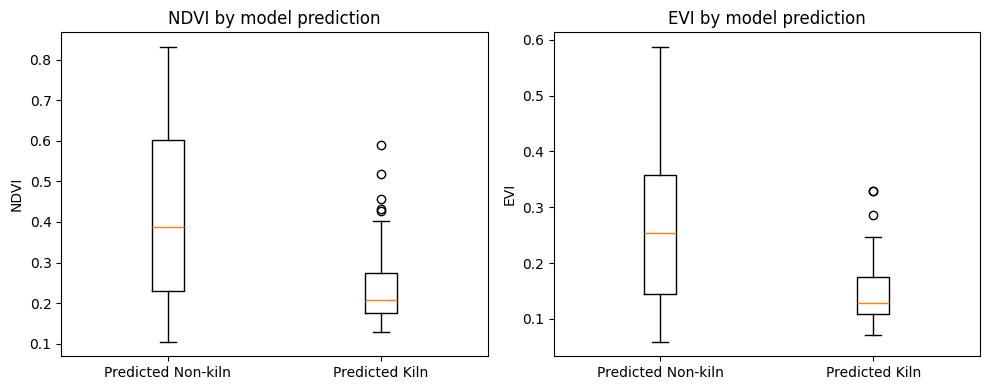

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['NDVI', 'EVI']):
    data = [env_df[env_df['model_pred']==0][col].dropna(), env_df[env_df['model_pred']==1][col].dropna()]
    ax.boxplot(data, labels=['Predicted Non-kiln', 'Predicted Kiln'])
    ax.set_title(f'{col} by model prediction')
    ax.set_ylabel(col)
plt.tight_layout()
plt.savefig('/content/ndvi_evi_by_prediction.png', dpi=150)
plt.show()

In [ ]:
tp_ndvi = env_df[env_df['confusion_cat']=='True Positive (caught kiln)']['NDVI'].dropna()
fn_ndvi = env_df[env_df['confusion_cat']=='False Negative (missed kiln)']['NDVI'].dropna()
t_stat, p_val = sps.ttest_ind(tp_ndvi, fn_ndvi)
print(f"TP vs FN NDVI: t={t_stat:.3f}, p={p_val:.4f}, Cohen's d={cohens_d(fn_ndvi, tp_ndvi):.3f}")

TP vs FN NDVI: t=-1.490, p=0.1392, Cohen's d=0.287


In [ ]:
from tqdm import tqdm
import pandas as pd

RING_DEFS = [(0, 100), (100, 250), (250, 500), (500, 1000)]

def get_ring_stats(lon, lat, rings, start='2025-12-01', end='2026-05-01'):
    point = ee.Geometry.Point([lon, lat])
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(point)
          .filterDate(start, end)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
          .median())
    nir = s2.select('B8').divide(10000)
    red = s2.select('B4').divide(10000)
    blue = s2.select('B2').divide(10000)
    ndvi = nir.subtract(red).divide(nir.add(red)).rename('NDVI')
    evi = nir.subtract(red).multiply(2.5).divide(
        nir.add(red.multiply(6)).subtract(blue.multiply(7.5)).add(1)
    ).rename('EVI')
    img = ndvi.addBands(evi)

    row = {}
    for inner, outer in rings:
        geom = point.buffer(outer) if inner == 0 else point.buffer(outer).difference(point.buffer(inner))
        stats = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=geom, scale=10, maxPixels=1e9).getInfo()
        row[f'NDVI_{inner}_{outer}'] = stats.get('NDVI')
        row[f'EVI_{inner}_{outer}'] = stats.get('EVI')
    return row

ring_results = []
for i, row in enumerate(tqdm(df_clean.itertuples(), total=len(df_clean))):
    try:
        stats = get_ring_stats(row.Longitude, row.Latitude, RING_DEFS)
        stats.update({'kiln_id': i, 'Type': row.Type})
        ring_results.append(stats)
    except Exception as e:
        ring_results.append({'kiln_id': i, 'error': str(e)})
    if i % 15 == 0:
        pd.DataFrame(ring_results).to_csv('/content/ring_analysis_partial.csv', index=False)

ring_wide = pd.DataFrame(ring_results)
ring_wide.to_csv('/content/ring_analysis_full.csv', index=False)
print(f"Completed: {len(ring_wide)} kilns")

100%|██████████| 108/108 [09:55<00:00,  5.52s/it]

Completed: 108 kilns


In [ ]:
long_rows = []
for _, r in ring_wide.iterrows():
    for inner, outer in RING_DEFS:
        long_rows.append({
            'kiln_id': r['kiln_id'], 'ring': f'{inner}-{outer}m',
            'NDVI': r.get(f'NDVI_{inner}_{outer}'), 'EVI': r.get(f'EVI_{inner}_{outer}'),
        })
ring_long = pd.DataFrame(long_rows).dropna()

print(ring_long.groupby('ring')[['NDVI','EVI']].agg(['mean','std','count']))

from statsmodels.stats.anova import AnovaRM
complete_kilns = ring_long.groupby('kiln_id').filter(lambda g: len(g) == len(RING_DEFS))

print("\nNDVI repeated-measures ANOVA across distance rings:")
print(AnovaRM(complete_kilns, depvar='NDVI', subject='kiln_id', within=['ring']).fit())
print("\nEVI repeated-measures ANOVA across distance rings:")
print(AnovaRM(complete_kilns, depvar='EVI', subject='kiln_id', within=['ring']).fit())

               NDVI                       EVI                
               mean       std count      mean       std count
ring                                                         
0-100m     0.221940  0.058291   108  0.141943  0.039891   108
100-250m   0.269407  0.052860   108  0.174055  0.035986   108
250-500m   0.301065  0.056305   108  0.194683  0.036518   108
500-1000m  0.318955  0.055828   108  0.204641  0.034255   108

NDVI repeated-measures ANOVA across distance rings:
               Anova
     F Value  Num DF  Den DF  Pr > F
------------------------------------
ring 134.8768 3.0000 321.0000 0.0000


EVI repeated-measures ANOVA across distance rings:
               Anova
     F Value  Num DF  Den DF  Pr > F
------------------------------------
ring 135.4199 3.0000 321.0000 0.0000



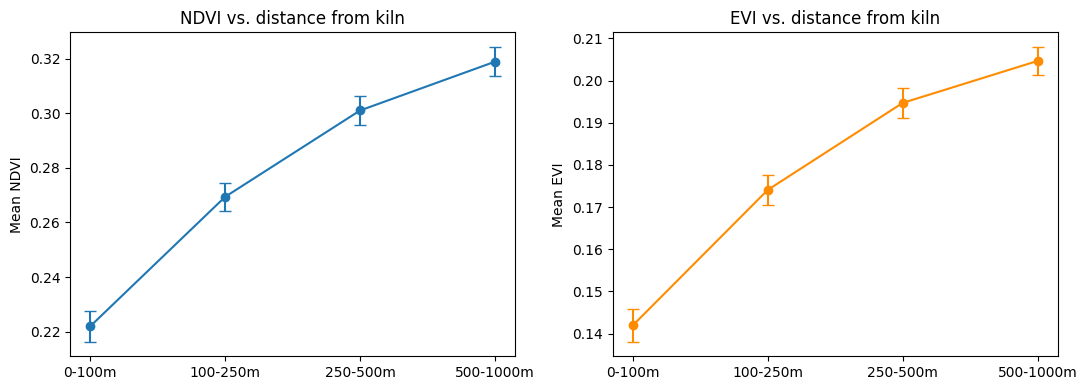

In [ ]:
import matplotlib.pyplot as plt

ring_order = [f'{i}-{o}m' for i,o in RING_DEFS]
means_ndvi = ring_long.groupby('ring')['NDVI'].mean().reindex(ring_order)
sems_ndvi = ring_long.groupby('ring')['NDVI'].sem().reindex(ring_order)
means_evi = ring_long.groupby('ring')['EVI'].mean().reindex(ring_order)
sems_evi = ring_long.groupby('ring')['EVI'].sem().reindex(ring_order)

fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].errorbar(range(len(ring_order)), means_ndvi, yerr=sems_ndvi, marker='o', capsize=4)
axes[0].set_xticks(range(len(ring_order))); axes[0].set_xticklabels(ring_order)
axes[0].set_ylabel('Mean NDVI'); axes[0].set_title('NDVI vs. distance from kiln')

axes[1].errorbar(range(len(ring_order)), means_evi, yerr=sems_evi, marker='o', capsize=4, color='darkorange')
axes[1].set_xticks(range(len(ring_order))); axes[1].set_xticklabels(ring_order)
axes[1].set_ylabel('Mean EVI'); axes[1].set_title('EVI vs. distance from kiln')

plt.tight_layout()
plt.savefig('/content/distance_decay.png', dpi=150)
plt.show()

Generating URL ...
Please wait ...
Data downloaded to /content/ndvi_valley.tif


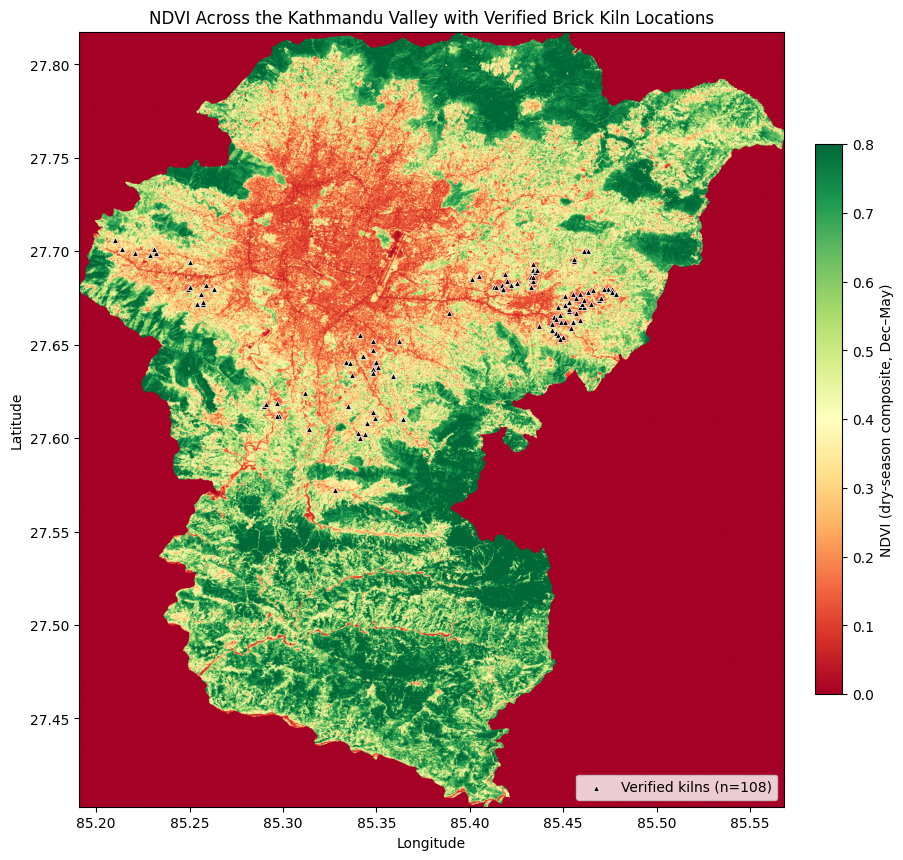

In [ ]:
import geemap, rasterio
import matplotlib.pyplot as plt

region = kathmandu_valley.geometry().bounds()
geemap.ee_export_image(ndvi_img.clip(kathmandu_valley), filename='/content/ndvi_valley.tif',
                        scale=30, region=region, file_per_band=False)

with rasterio.open('/content/ndvi_valley.tif') as src:
    ndvi_array = src.read(1)
    b = src.bounds

fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(ndvi_array, cmap='RdYlGn', vmin=0, vmax=0.8, extent=[b.left, b.right, b.bottom, b.top])
ax.scatter(df_clean['Longitude'], df_clean['Latitude'], c='black', s=18, marker='^',
           edgecolors='white', linewidths=0.5, label=f'Verified kilns (n={len(df_clean)})')
cbar = plt.colorbar(im, ax=ax, fraction=0.036, pad=0.04)
cbar.set_label('NDVI (dry-season composite, Dec–May)')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('NDVI Across the Kathmandu Valley with Verified Brick Kiln Locations')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('/content/ndvi_valley_publication.png', dpi=200)
plt.show()

In [ ]:
import statsmodels.formula.api as smf

ring_order_map = {name: i for i, name in enumerate(['0-100m','100-250m','250-500m','500-1000m'])}
complete_kilns['ring_num'] = complete_kilns['ring'].map(ring_order_map)

md_ndvi = smf.mixedlm("NDVI ~ ring_num", complete_kilns, groups=complete_kilns["kiln_id"]).fit()
md_evi = smf.mixedlm("EVI ~ ring_num", complete_kilns, groups=complete_kilns["kiln_id"]).fit()
print("NDVI trend:", md_ndvi.params['ring_num'], "p =", md_ndvi.pvalues['ring_num'])
print("EVI trend:", md_evi.params['ring_num'], "p =", md_evi.pvalues['ring_num'])

/tmp/ipykernel_1383/1711364520.py:6: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  md_ndvi = smf.mixedlm("NDVI ~ ring_num", complete_kilns, groups=complete_kilns["kiln_id"]).fit()


NDVI trend: 0.032270443788854054 p = 7.542753167494609e-83
EVI trend: 0.020872005095391798 p = 7.9965760483559295e-81


/tmp/ipykernel_1383/1711364520.py:7: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  md_evi = smf.mixedlm("EVI ~ ring_num", complete_kilns, groups=complete_kilns["kiln_id"]).fit()


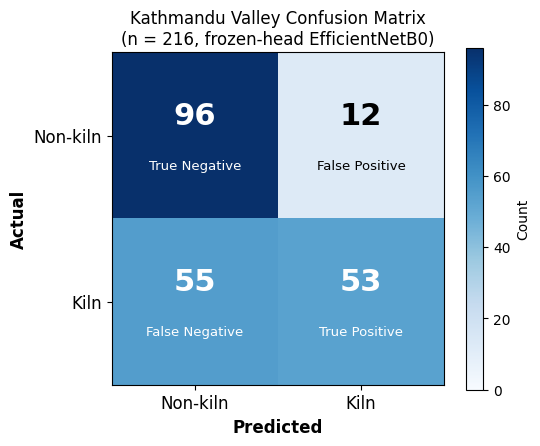

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(y_kathmandu, preds)  # you already computed this earlier
labels = ['Non-kiln', 'Kiln']

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max())
ax.set_xticks([0, 1]); ax.set_xticklabels(labels, fontsize=12)
ax.set_yticks([0, 1]); ax.set_yticklabels(labels, fontsize=12)
ax.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax.set_ylabel('Actual', fontsize=12, fontweight='bold')
ax.set_title('Kathmandu Valley Confusion Matrix\n(n = 216, frozen-head EfficientNetB0)')

quadrant_names = [['True Negative', 'False Positive'], ['False Negative', 'True Positive']]
for i in range(2):
    for j in range(2):
        val = cm[i, j]
        color = 'white' if val > cm.max() * 0.5 else 'black'
        ax.text(j, i - 0.12, f'{val}', ha='center', va='center', fontsize=22, fontweight='bold', color=color)
        ax.text(j, i + 0.18, quadrant_names[i][j], ha='center', va='center', fontsize=9.5, color=color)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.06, label='Count')
plt.tight_layout()
plt.savefig('/content/kathmandu_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()